# K-Means y Clasificación Supervisada - California Housing

## Paso 1: Carga del conjunto de datos y división en Train / Test
Cargamos `housing.csv`, seleccionamos únicamente las variables de interés (`Latitude`, `Longitude` y `MedInc`) y dividimos el dataset en conjunto de entrenamiento (80%) y prueba (20%).

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Cargar el dataset desde data/raw/housing.csv
total_data = pd.read_csv("../data/raw/housing.csv")

# 2. Filtrar únicamente las columnas de interés
data = total_data[["Latitude", "Longitude", "MedInc"]].copy()

# 3. Dividir en conjunto de entrenamiento (80%) y prueba (20%)
X_train, X_test = train_test_split(data, test_size=0.2, random_state=42)

print(f"Dimensiones totales (filtrado): {data.shape}")
print(f"Dimensiones X_train: {X_train.shape}")
print(f"Dimensiones X_test:  {X_test.shape}")
print(f"\nValores nulos por columna:\n{data.isnull().sum()}")
X_train.head()

Dimensiones totales (filtrado): (20640, 3)
Dimensiones X_train: (16512, 3)
Dimensiones X_test:  (4128, 3)

Valores nulos por columna:
Latitude     0
Longitude    0
MedInc       0
dtype: int64


,Latitude,Longitude,MedInc
14196,32.71,-117.03,3.2596
8267,33.77,-118.16,3.8125
17445,34.66,-120.48,4.1563
14265,32.69,-117.11,1.9425
2271,36.78,-119.80,3.5542


## Paso 2: Construcción del modelo K-Means (6 clusters)
Entrenamos `KMeans` con 6 clusters sobre `X_train`, añadimos la columna `cluster` categorizada y graficamos el diagrama de puntos para analizar la distribución geográfica y de ingresos.

Tipo de dato de 'cluster': category

Conteo de casas por cluster en train:
cluster
0    2455
1    3807
2    1280
3    4368
4     246
5    4356
Name: count, dtype: int64

Promedio de Latitude, Longitude y MedInc por cluster:
         Latitude  Longitude  MedInc
cluster                             
0           37.69    -121.92    5.38
1           33.89    -118.00    4.35
2           33.85    -118.04    6.94
3           34.04    -118.02    2.43
4           35.88    -120.28   11.75
5           38.14    -121.62    2.74


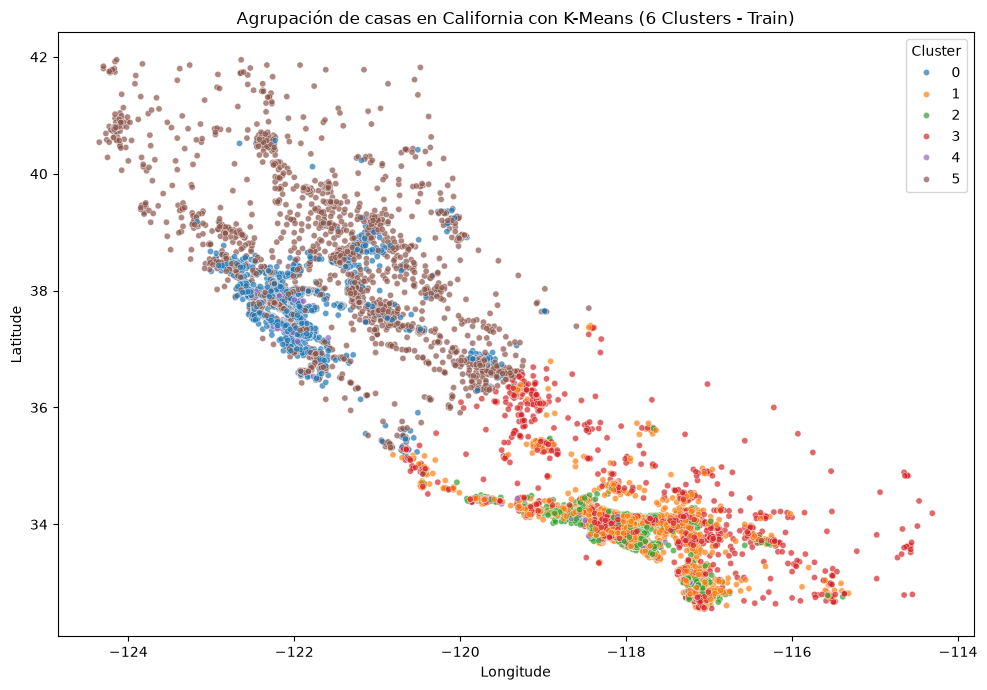

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# 1. Entrenar K-Means con 6 clusters sobre el conjunto de entrenamiento
model_kmeans = KMeans(n_clusters=6, random_state=42)
model_kmeans.fit(X_train[["Latitude", "Longitude", "MedInc"]])

# 2. Almacenar el cluster en X_train y convertirlo a categoría
X_train["cluster"] = pd.Series(model_kmeans.labels_, index=X_train.index, dtype="category")

print("Tipo de dato de 'cluster':", X_train["cluster"].dtype)
print("\nConteo de casas por cluster en train:")
print(X_train["cluster"].value_counts().sort_index())
print("\nPromedio de Latitude, Longitude y MedInc por cluster:")
print(X_train.groupby("cluster", observed=False)[["Latitude", "Longitude", "MedInc"]].mean().round(2))

# 3. Graficar en un diagrama de puntos
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=X_train,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    s=20,
    alpha=0.7
)
plt.title("Agrupación de casas en California con K-Means (6 Clusters - Train)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Paso 3: Predicción con el conjunto de Test
Utilizamos el modelo `KMeans` ya entrenado para predecir el cluster de cada vivienda en `X_test` y añadimos los puntos al gráfico anterior para confirmar visualmente que la asignación es consistente.

Conteo de casas por cluster en test:
cluster
0     561
1     983
2     299
3    1111
4      62
5    1112
Name: count, dtype: int64


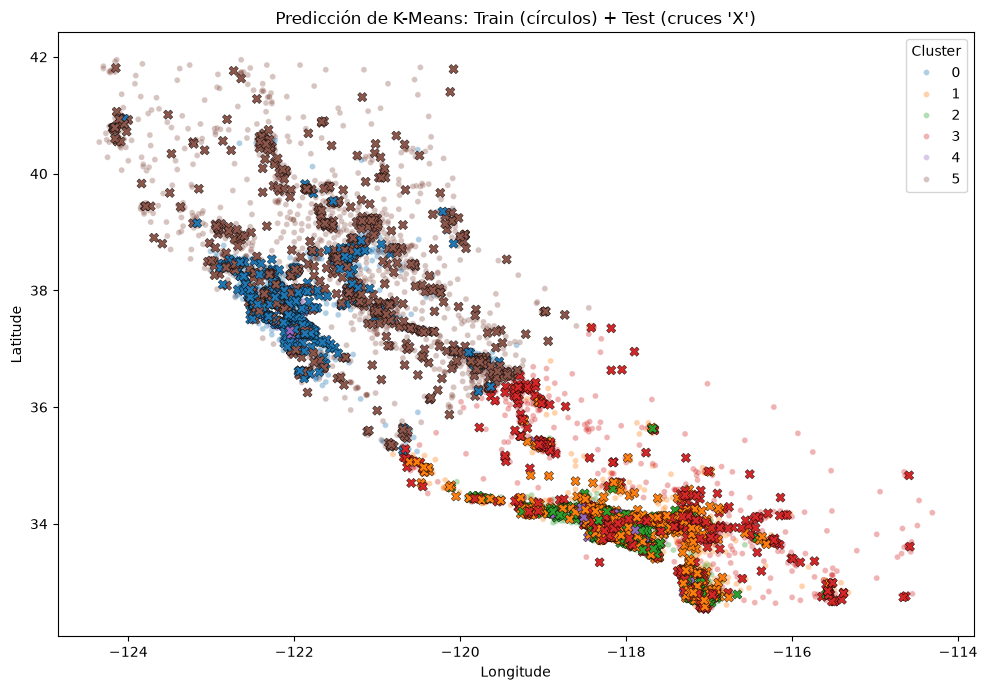

In [3]:
# 1. Predecir los clusters para el conjunto de prueba (test)
test_clusters = model_kmeans.predict(X_test[["Latitude", "Longitude", "MedInc"]])
X_test["cluster"] = pd.Series(test_clusters, index=X_test.index, dtype="category")

print("Conteo de casas por cluster en test:")
print(X_test["cluster"].value_counts().sort_index())

# 2. Graficar los puntos de Train y superponer los puntos de Test
plt.figure(figsize=(10, 7))

# Puntos de entrenamiento (fondo más suave)
sns.scatterplot(
    data=X_train,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    s=18,
    alpha=0.35
)

# Puntos de prueba superpuestos (marcador 'X' con borde para distinguirlos)
sns.scatterplot(
    data=X_test,
    x="Longitude",
    y="Latitude",
    hue="cluster",
    palette="tab10",
    s=45,
    marker="X",
    edgecolor="black",
    linewidth=0.3,
    legend=False
)

plt.title("Predicción de K-Means: Train (círculos) + Test (cruces 'X')")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Paso 4: Entrenamiento de un modelo de clasificación supervisada
Con los clusters ya generados como etiquetas en `train` y `test`, separamos las variables predictoras (`Latitude`, `Longitude`, `MedInc`) de la variable objetivo (`cluster`) y entrenamos un modelo `RandomForestClassifier` para evaluar qué tan bien clasifica nuevas viviendas.

Accuracy en Test: 0.9959 (99.59%)

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       561
           1       1.00      1.00      1.00       983
           2       0.99      1.00      0.99       299
           3       1.00      1.00      1.00      1111
           4       0.98      0.97      0.98        62
           5       1.00      0.99      1.00      1112

    accuracy                           1.00      4128
   macro avg       0.99      0.99      0.99      4128
weighted avg       1.00      1.00      1.00      4128



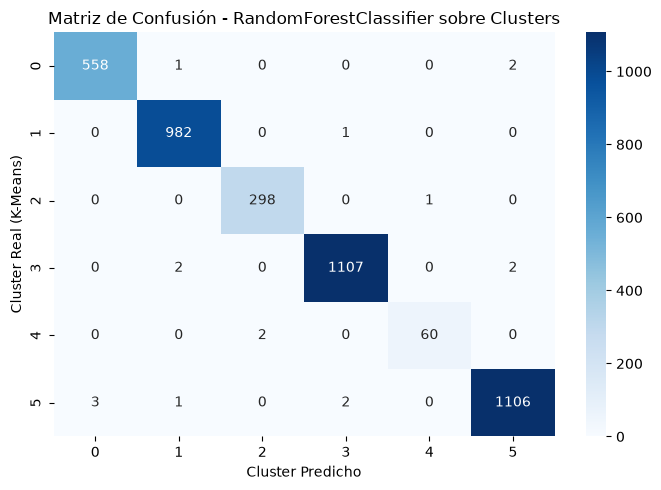

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Separar características (X) y etiquetas generadas por K-Means (y)
features = ["Latitude", "Longitude", "MedInc"]
X_train_sup = X_train[features]
y_train_sup = X_train["cluster"]

X_test_sup = X_test[features]
y_test_sup = X_test["cluster"]

# 2. Entrenar el clasificador supervisado (Random Forest)
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train_sup, y_train_sup)

# 3. Predecir sobre el conjunto de prueba y obtener estadísticas
y_pred = model_rf.predict(X_test_sup)
acc = accuracy_score(y_test_sup, y_pred)

print(f"Accuracy en Test: {acc:.4f} ({acc * 100:.2f}%)\n")
print("Reporte de Clasificación:")
print(classification_report(y_test_sup, y_pred))

# 4. Visualizar Matriz de Confusión
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_test_sup, y_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de Confusión - RandomForestClassifier sobre Clusters")
plt.xlabel("Cluster Predicho")
plt.ylabel("Cluster Real (K-Means)")
plt.tight_layout()
plt.show()

## Paso 5: Guardado de los modelos y conjuntos procesados
Almacenamos tanto el modelo no supervisado (`KMeans`) como el modelo supervisado (`RandomForestClassifier`) en la carpeta `models/`, y guardamos las particiones procesadas en `data/processed/`.

In [5]:
import os
from pickle import dump

# 1. Asegurar que las carpetas de salida existan
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

# 2. Guardar ambos modelos con pickle
kmeans_path = "../models/k-means_default_42.sav"
rf_path = "../models/random_forest_classifier_default_42.sav"

dump(model_kmeans, open(kmeans_path, "wb"))
dump(model_rf, open(rf_path, "wb"))

# 3. Guardar conjuntos de train y test procesados con su columna 'cluster'
X_train.to_csv("../data/processed/clean_train.csv", index=False)
X_test.to_csv("../data/processed/clean_test.csv", index=False)

print("Modelos guardados exitosamente en '../models/':")
print(" -", kmeans_path)
print(" -", rf_path)
print("Datos procesados guardados en '../data/processed/'.")

Modelos guardados exitosamente en '../models/':
 - ../models/k-means_default_42.sav
 - ../models/random_forest_classifier_default_42.sav
Datos procesados guardados en '../data/processed/'.
